In [1]:
# 导库
%reset -f
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
# import seaborn as sns
import os
import warnings
warnings.filterwarnings('ignore')
import ast
import re
import seaborn as sns
plt.style.use('ggplot')

# NCA

In [2]:
path = r'D:\科研\7_project\CC_REST_FUSIO\RESULT_ON_GPU_STATION\V5\CC_CV_FUSIO_V2_liner_att_layer\plot_for_paper\容量衰退和循环分布\CC_CV_1500_SAMPLE_10.pkl'
with open(path,'rb') as f:
    data = pd.read_pickle(f)

In [3]:
print(data.keys())

Index(['CC_vol_0', 'CC_vol_1', 'CC_vol_2', 'CC_vol_3', 'CC_vol_4', 'CC_vol_5',
       'CC_vol_6', 'CC_vol_7', 'CC_vol_8', 'CC_vol_9',
       ...
       'RE_vol_144', 'RE_vol_145', 'RE_vol_146', 'RE_vol_147', 'RE_vol_148',
       'RE_vol_149', 'RE_vol_150', 'cycle', 'capacity', 'id'],
      dtype='object', length=305)


In [4]:
data_1 = data[[ 'cycle', 'capacity', 'id']]
battery_id = data['id'].unique()

In [5]:
# 对series每个元素进行操作
def get_id(x):
    # #号前面的就是id，再删除最后的-
    return x.split('#')[0]
condition = data['id'].apply(get_id).unique()
condition

array(['25-025_1-', '25-05_1-', '25-1_1-', '35-05_1-', '45-05_1-'],
      dtype=object)

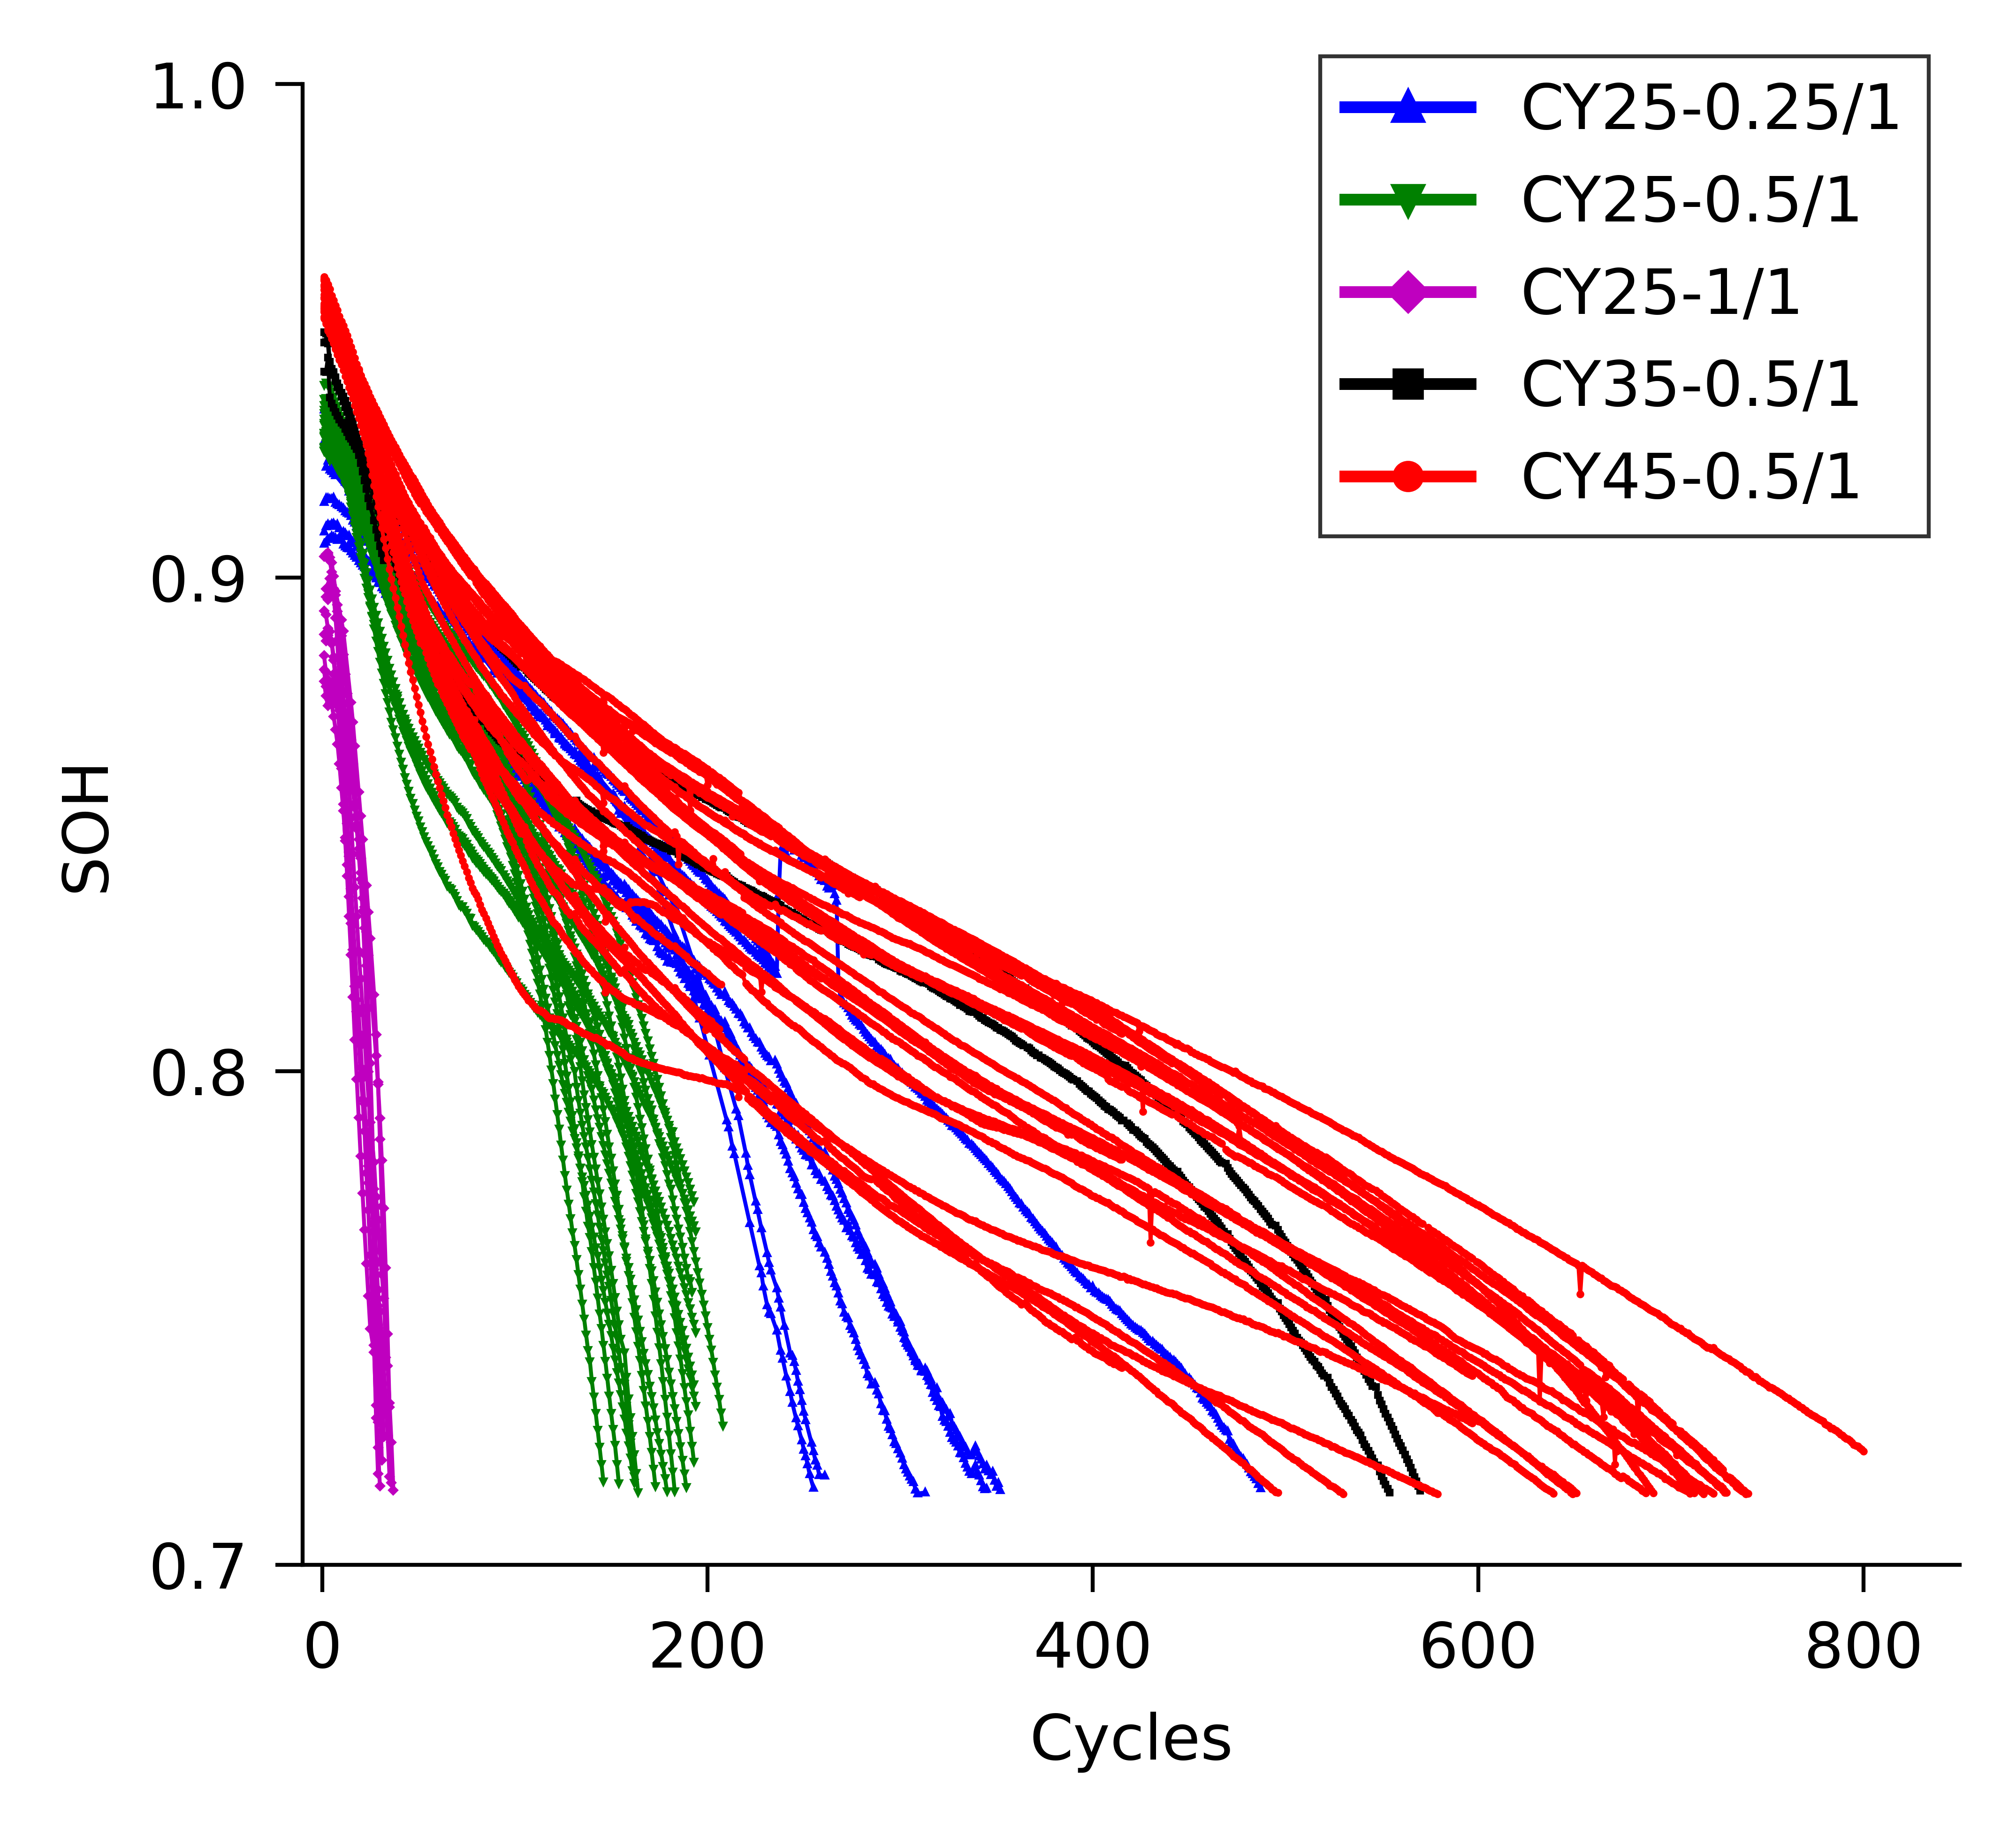

In [11]:
plt.style.use('default')
cm = 1/2.54
fontsize = 8
plt.figure(figsize=(17/2*cm*1.1,17/2*cm),dpi=1200)
legend = []
for i in battery_id:
    # 画在一张图上
    if i.split('#')[0] == condition[0]:
        # 标记为上三角，蓝色
        marker = '^'
        color = 'b'
    elif i.split('#')[0] == condition[1]:
        # 下三角，浅绿色
        marker = 'v'
        color = 'g'
    elif i.split('#')[0] == condition[2]:
        # 菱形，浅紫色
        marker = 'D'
        color = 'm'
    elif i.split('#')[0] == condition[3]:
        # 正方形，黑色
        marker = 's'
        color = 'k'
    elif i.split('#')[0] == condition[4]:
        # 圆形，红色
        marker = 'o'
        color = 'r'   
    plt.plot(data_1[data_1['id']==i]['cycle'],data_1[data_1['id']==i]['capacity']/3500, 
             color=color,  linestyle='-', marker=marker, markersize=0.5, 
             markerfacecolor=color, markeredgewidth=0.5, linewidth=0.5) 
    plt.xlabel('Cycles',fontsize=fontsize)
    plt.ylabel('SOH',fontsize=fontsize)
    # 删除上边框和右边框
    ax = plt.gca()
    ax.spines['top'].set_visible(False)
    ax.spines['right'].set_visible(False)
    # 左边框和下边框的线条变细
    ax.spines['left'].set_linewidth(0.5)
    ax.spines['bottom'].set_linewidth(0.5)
    # 刻度线变细
    ax.tick_params(width=0.5)
    plt.xticks([i for i in range(0,1000,200)],fontsize=fontsize)
    plt.yticks([i*0.1 for i in range(7,11,1)],fontsize=fontsize)
    # 设置x轴和y轴长度一致
    # plt.axis('square')
    plt.xlim(-10, 850)
    plt.ylim(0.7, 1)
# 设置图例
# 上三角，蓝色对应的图例
legend.append(plt.plot([],[],color='b',marker='^',markersize=3, linestyle='-', label='CY25-0.25/1')[0])
# 下三角，浅绿色对应的图例
legend.append(plt.plot([],[],color='g',marker='v',markersize=3, linestyle='-', label='CY25-0.5/1')[0])
# 菱形，浅紫色对应的图例
legend.append(plt.plot([],[],color='m',marker='D',markersize=3, linestyle='-', label='CY25-1/1')[0])
# 正方形，黑色对应的图例
legend.append(plt.plot([],[],color='k',marker='s',markersize=3, linestyle='-', label='CY35-0.5/1')[0])
# 圆形，红色对应的图例
legend.append(plt.plot([],[],color='r',marker='o',markersize=3, linestyle='-', label='CY45-0.5/1')[0])
# 设置图例左下角位置为[200,3100],黑色边框
legend= plt.legend(handles=legend, loc='upper right', 
                   bbox_to_anchor=(1,1.04), frameon=True, 
                   edgecolor='black', fontsize=fontsize,fancybox=False, shadow=False)
legend.get_frame().set_linewidth(0.5)
plt.tight_layout()
plt.savefig(r'D:\My_program\long\code\2-数据分析\NCA衰退曲线',dpi=1200)
plt.show() 

In [ ]:
# 各工况循环数分布
plt.style.use('default')
cm = 1/2.54
fontsize = 8
cycle_1 = []
cycle_2 = []
cycle_3 = []
cycle_4 = []
cycle_5 = []
for i in battery_id:
    if i.split('#')[0] == condition[0]:
        cycle = data_1[data_1['id']==i]['cycle'].max()
        cycle_1.append(cycle)
    if i.split('#')[0] == condition[1]:
        cycle = data_1[data_1['id']==i]['cycle'].max()
        cycle_2.append(cycle)
    if i.split('#')[0] == condition[2]:
        cycle = data_1[data_1['id']==i]['cycle'].max()
        cycle_3.append(cycle)
        # 删除大于1000的循环数
        if cycle > 1000:
            cycle_3.remove(cycle)
    if i.split('#')[0] == condition[3]:
        cycle = data_1[data_1['id']==i]['cycle'].max()
        cycle_4.append(cycle)
    if i.split('#')[0] == condition[4]:
        cycle = data_1[data_1['id']==i]['cycle'].max()
        cycle_5.append(cycle)
plt.figure(figsize=(17/3/5*cm,17/3/2*cm),dpi=1200)
# 使用sns.swarmplot画出散点图，标记和之前的一样
sns.swarmplot(data=cycle_1, color='b',  marker='^', size=2)
sns.swarmplot(data=cycle_2, color='g',  marker='v', size=2)
sns.swarmplot(data=cycle_3, color='m',  marker='D', size=2)
sns.swarmplot(data=cycle_4, color='k',  marker='s', size=2)
sns.swarmplot(data=cycle_5, color='r',  marker='o', size=2)
plt.xlabel('',fontsize=fontsize)
plt.ylabel('Cycles',fontsize=fontsize)
plt.yticks([0,500,1000],fontsize=fontsize)
plt.ylim(0 ,1000)
# 所有边框线条变细
ax = plt.gca()
ax.spines['top'].set_linewidth(0.5)
ax.spines['right'].set_linewidth(0.5)
ax.spines['left'].set_linewidth(0.5)
ax.spines['bottom'].set_linewidth(0.5)
# 刻度线变细
ax.tick_params(width=0.5)
# 设置x刻度不可见
plt.xticks([])
plt.tight_layout()
plt.savefig(r'D:\My_program\long\code\2-数据分析\NCA衰退曲线',dpi=1200,bbox_inches='tight')

# NCM

In [22]:
path = r'D:\科研\7_project\CC_REST_FUSIO\RESULT_ON_GPU_STATION\V5\CC_CV_FUSIO_V2_liner_att_layer\TL_learning\data_processing\NCM_SAMPLE_10.pkl'
with open(path,'rb') as f:
    data = pd.read_pickle(f)

In [23]:
print(data.keys())

Index([         0,          1,          2,          3,          4,          5,
                6,          7,          8,          9,
       ...
              144,        145,        146,        147,        148,        149,
              150,    'cycle', 'capacity',       'id'],
      dtype='object', length=305)


In [24]:
data_1 = data[[ 'cycle', 'capacity', 'id']]
battery_id = data['id'].unique()

In [25]:
# 对series每个元素进行操作
def get_id(x):
    # #号前面的就是id，再删除最后的-
    return x.split('#')[0]
condition = data['id'].apply(get_id).unique()
condition

array(['25-05_1-', '35-05_1-', '45-05_1-'], dtype=object)

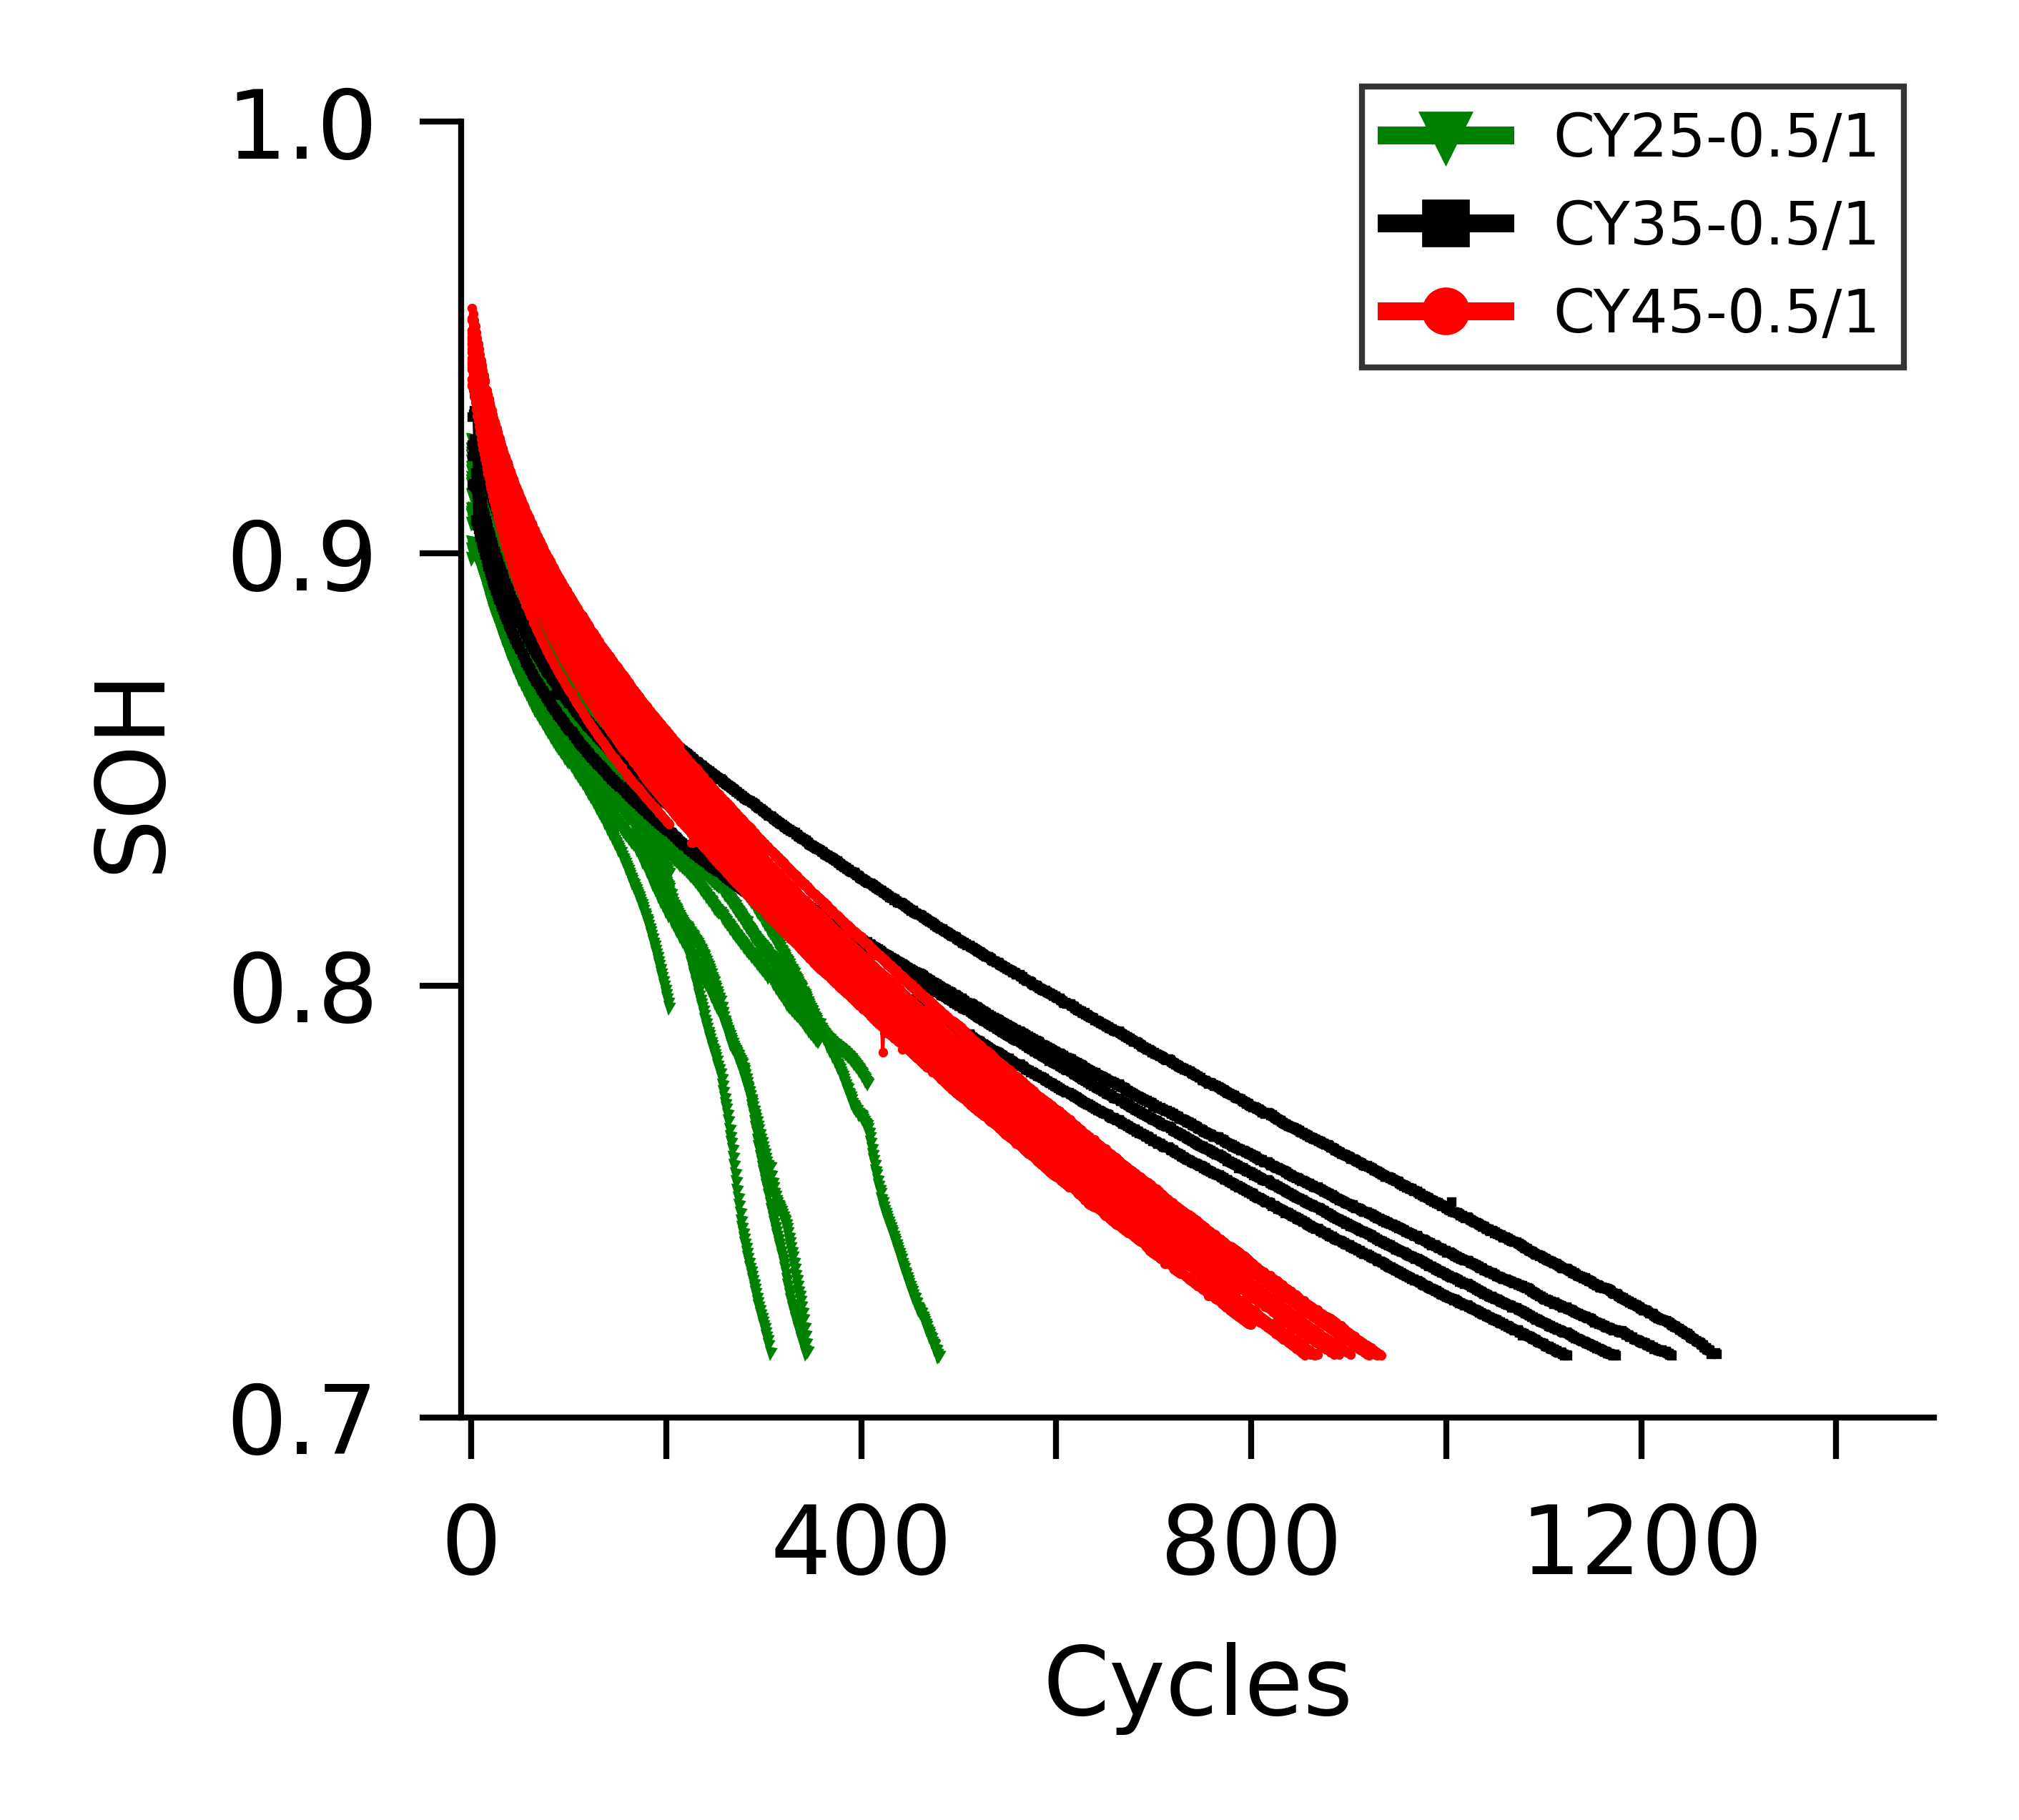

In [26]:
plt.style.use('default')
cm = 1/2.54
fontsize = 8
plt.figure(figsize=(17/3*cm*1.1,17/3*cm),dpi=1200)
legend = []
for i in battery_id:
    # 画在一张图上
    if i.split('#')[0] == condition[0]:
        # 下三角，浅绿色
        marker = 'v'
        color = 'g'
    elif i.split('#')[0] == condition[1]:
        # 正方形，黑色
        marker = 's'
        color = 'k'
    elif i.split('#')[0] == condition[2]:
        # 圆形，红色
        marker = 'o'
        color = 'r'
    plt.plot(data_1[data_1['id']==i]['cycle'],data_1[data_1['id']==i]['capacity']/3500, 
             color=color,  linestyle='-', marker=marker, markersize=0.3, 
             markerfacecolor=color, markeredgewidth=0.5,
             linewidth=0.3) 
    plt.xlabel('Cycles',fontsize=fontsize)
    plt.ylabel('SOH',fontsize=fontsize)
    # 删除上边框和右边框
    ax = plt.gca()
    ax.spines['top'].set_visible(False)
    ax.spines['right'].set_visible(False)
    # 左边框和下边框的线条变细
    ax.spines['left'].set_linewidth(0.5)
    ax.spines['bottom'].set_linewidth(0.5)
    # 刻度线变细
    ax.tick_params(width=0.5)
    # 设置x轴刻度位置
    xticks = np.arange(0, 1800, 200)

    # 将奇数位置的刻度标签替换为空值
    xtick_labels = [str(i*200) if i % 2 == 0 else '' for i in range(len(xticks))]

    # 应用刻度标签
    plt.xticks(xticks, xtick_labels, fontsize=fontsize)
    plt.yticks([i*0.1 for i in range(7,11,1)],fontsize=fontsize)
    # 设置x轴和y轴长度一致
    # plt.axis('square')
    plt.xlim(-10, 1500)
    plt.ylim(0.7, 1)
# 设置图例
# 下三角，浅绿色对应的图例
legend.append(plt.plot([],[],color='g',marker='v',markersize=3, linestyle='-', label='CY25-0.5/1')[0])
# 正方形，黑色对应的图例
legend.append(plt.plot([],[],color='k',marker='s',markersize=3, linestyle='-', label='CY35-0.5/1')[0])
# 圆形，红色对应的图例
legend.append(plt.plot([],[],color='r',marker='o',markersize=3, linestyle='-', label='CY45-0.5/1')[0])
# 设置图例左下角位置为[200,3100],黑色边框
legend= plt.legend(handles=legend, loc='upper right', bbox_to_anchor=(1,1.05), frameon=True, edgecolor='black', fontsize=5,fancybox=False, shadow=False)
legend.get_frame().set_linewidth(0.5)
plt.tight_layout()
plt.savefig(r'D:\My_program\long\code\2-数据分析\NCM衰退曲线',dpi=1200)
plt.show() 

In [ ]:
# 各工况循环数分布
plt.style.use('default')
cm = 1/2.54
fontsize = 8
cycle_1 = []
cycle_2 = []
cycle_3 = []
for i in battery_id:
    if i.split('#')[0] == condition[0]:
        cycle = data_1[data_1['id']==i]['cycle'].max()
        cycle_1.append(cycle)
    if i.split('#')[0] == condition[1]:
        cycle = data_1[data_1['id']==i]['cycle'].max()
        cycle_2.append(cycle)
    if i.split('#')[0] == condition[2]:
        cycle = data_1[data_1['id']==i]['cycle'].max()
        cycle_3.append(cycle)
plt.figure(figsize=(17/3/5*cm,17/3/2*cm),dpi=1200,facecolor='none')
# 使用sns.swarmplot画出散点图，标记和之前的一样
sns.swarmplot(data=cycle_1, color='g',  marker='v', size=2)
sns.swarmplot(data=cycle_2, color='k',  marker='s', size=2)
sns.swarmplot(data=cycle_3, color='r',  marker='o', size=2)
plt.xlabel('NCM',fontsize=fontsize)
plt.ylabel('Cycles',fontsize=fontsize)
plt.yticks([0,500,1000,1500],fontsize=fontsize)
plt.ylim(0 ,1500)
# 所有边框线条变细
ax = plt.gca()
ax.spines['top'].set_linewidth(0.5)
ax.spines['right'].set_linewidth(0.5)
ax.spines['left'].set_linewidth(0.5)
ax.spines['bottom'].set_linewidth(0.5)
# 刻度线变细
ax.tick_params(width=0.5)
plt.tight_layout()
plt.savefig(r'D:\科研\7_project\CC_REST_FUSIO\RESULT_ON_GPU_STATION\V5\CC_CV_FUSIO_V2_liner_att_layer\plot_for_paper\NCM循环数分布.jpg',dpi=1200,bbox_inches='tight',transparent=True)

# NCM+NCA

In [17]:
path = r'D:\科研\7_project\CC_REST_FUSIO\RESULT_ON_GPU_STATION\V5\CC_CV_FUSIO_V2_liner_att_layer\TL_learning\data_processing\NCMA_SAMPLE_10.pkl'
with open(path,'rb') as f:
    data = pd.read_pickle(f)

In [18]:
print(data.keys())

Index([         0,          1,          2,          3,          4,          5,
                6,          7,          8,          9,
       ...
              144,        145,        146,        147,        148,        149,
              150,    'cycle', 'capacity',       'id'],
      dtype='object', length=305)


In [19]:
data_1 = data[[ 'cycle', 'capacity', 'id']]
battery_id = data['id'].unique()

In [20]:
# 对series每个元素进行操作
def get_id(x):
    # #号前面的就是id，再删除最后的-
    return x.split('#')[0]
condition = data['id'].apply(get_id).unique()
condition

array(['25-05_1-', '25-05_2-', '25-05_4-'], dtype=object)

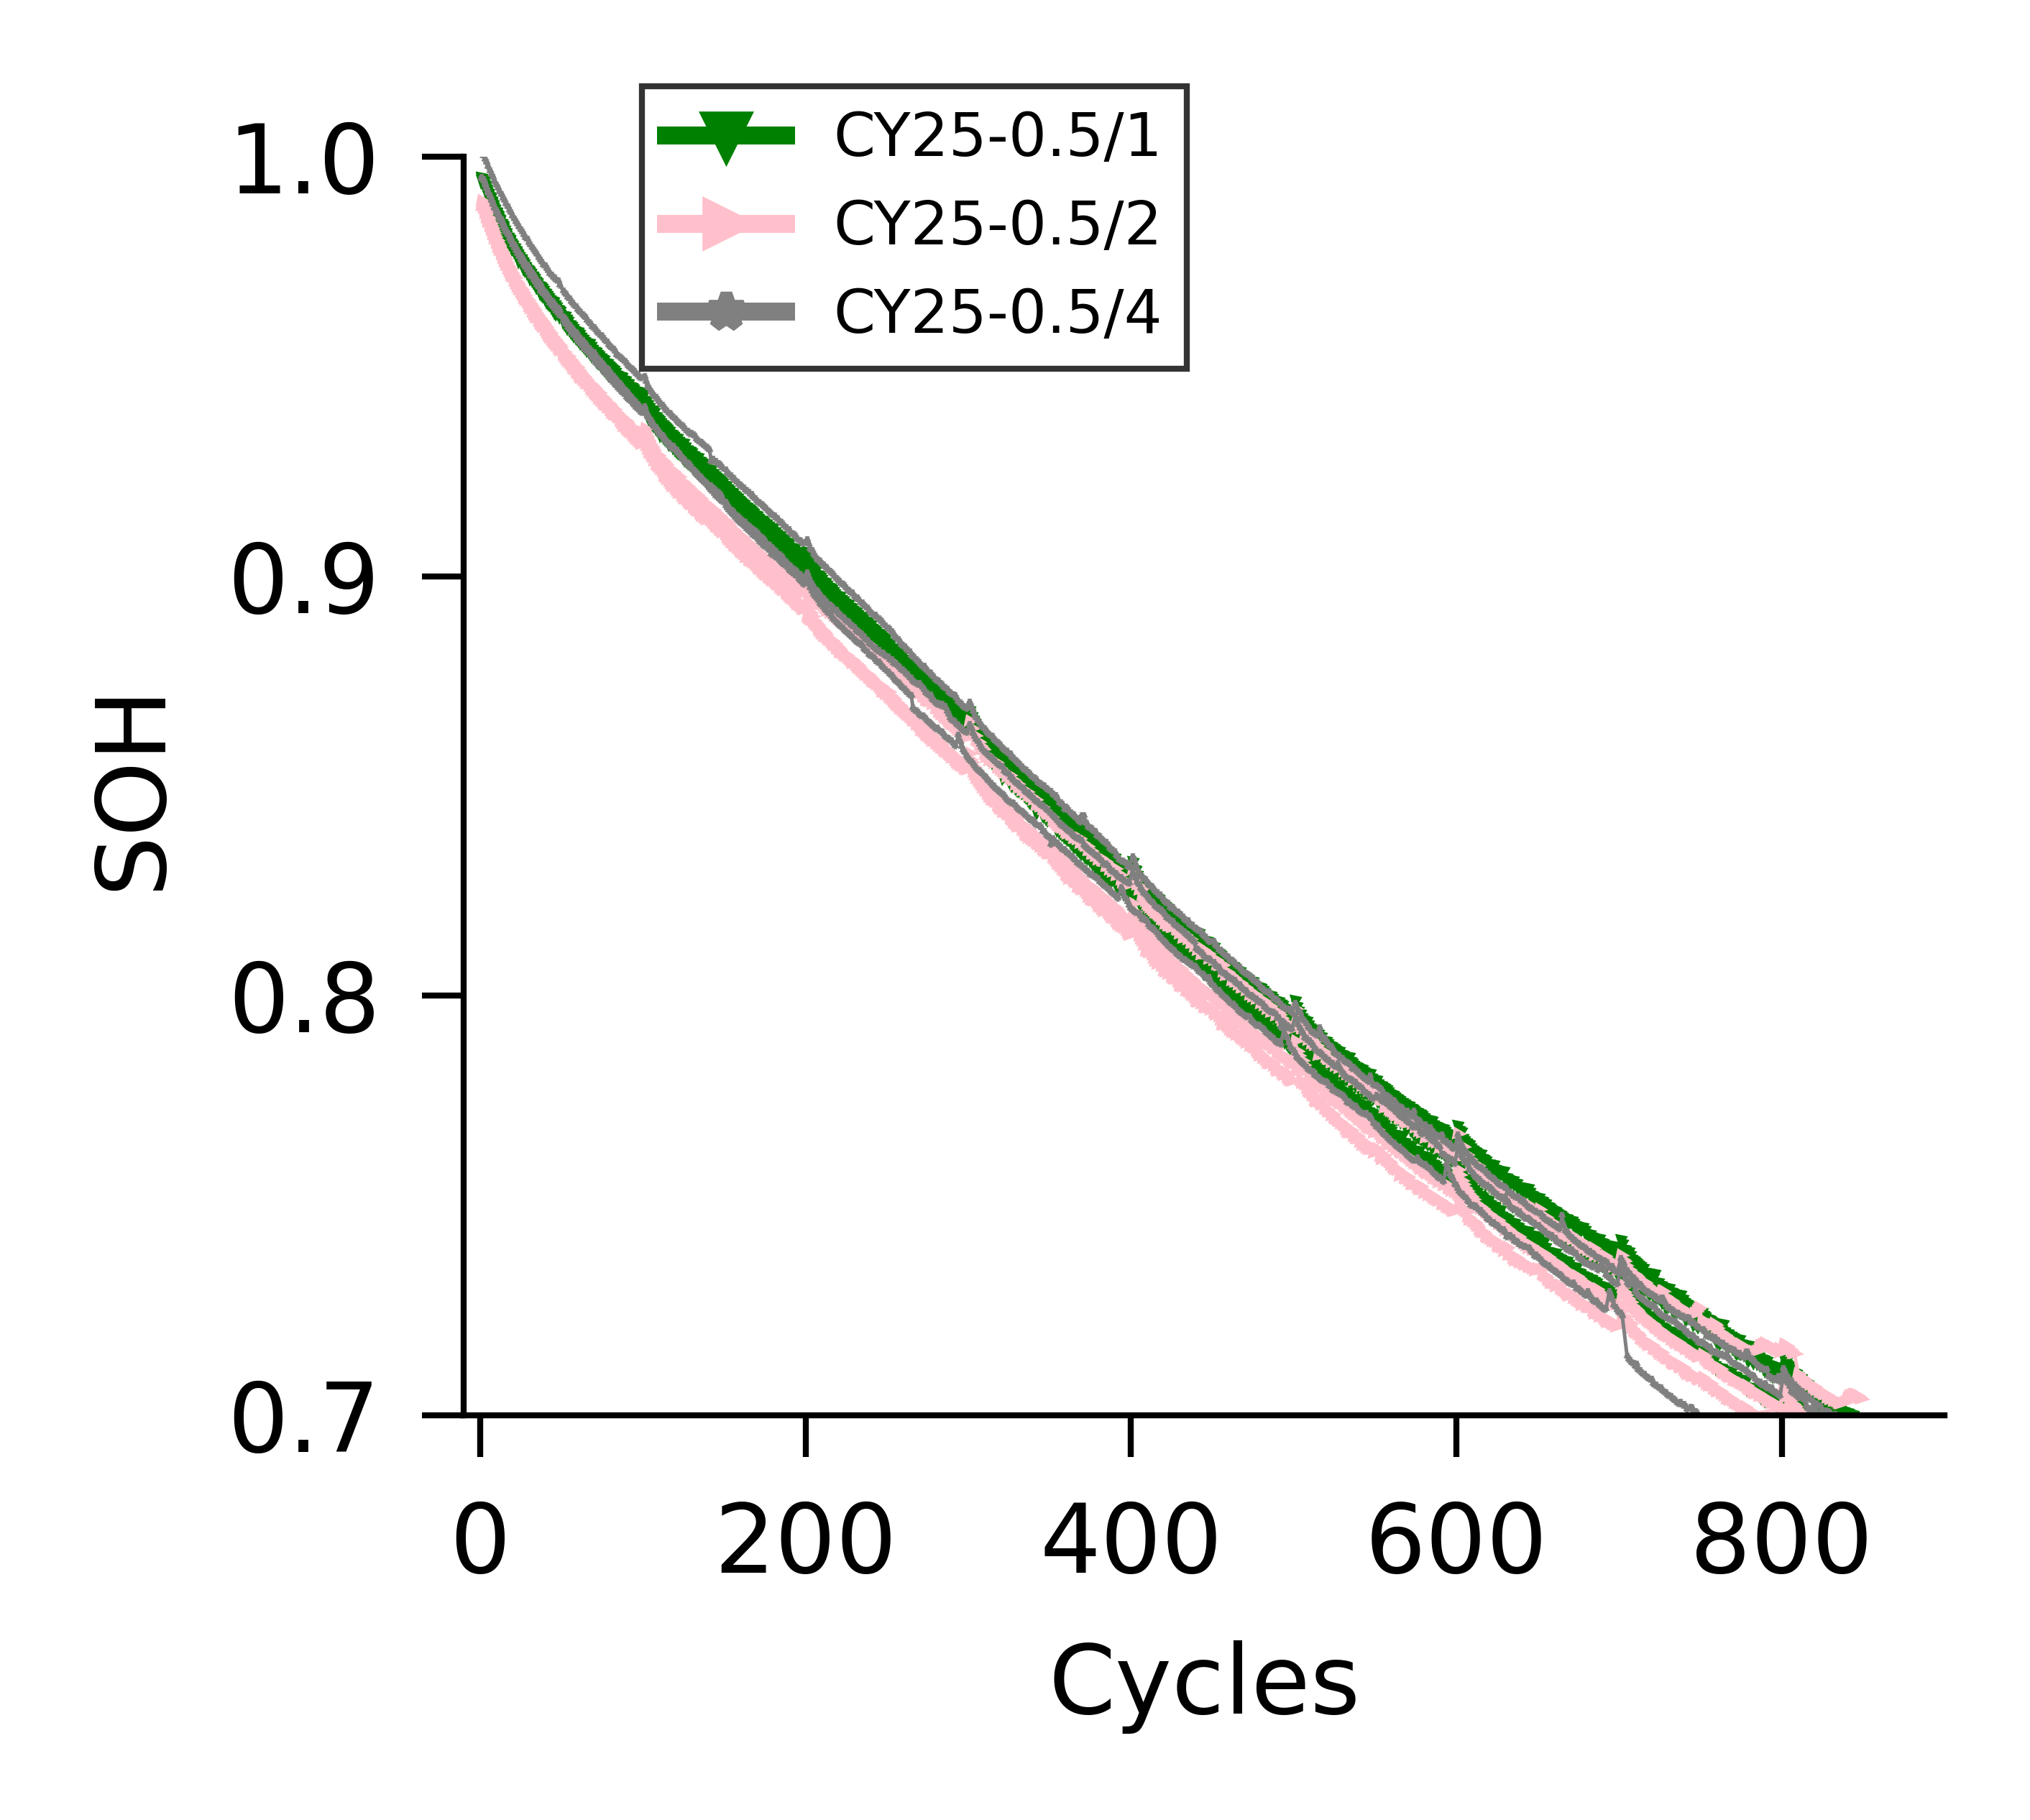

In [21]:
plt.style.use('default')
cm = 1/2.54
fontsize = 8
plt.figure(figsize=(17/3*cm*1.1,17/3*cm),dpi=1200)
legend = []
for i in battery_id:
    # 画在一张图上
    if i.split('#')[0] == condition[0]:
        # 下三角，绿色
        marker = 'v'
        color = 'g'
    elif i.split('#')[0] == condition[1]:
        # 右三角，粉色
        marker = '>'
        color = 'pink'
    elif i.split('#')[0] == condition[2]:
        # 星形，灰色
        marker = '*'
        color = 'grey'
    # 只读取soh大于等于0.7的数据
    index = data_1[data_1['id']==i]['capacity']/2500 >= 0.7
    plt.plot(data_1[data_1['id']==i]['cycle'][index],data_1[data_1['id']==i]['capacity'][index]/2500, 
    color=color,  linestyle='-', marker=marker, markersize=0.3,
      markerfacecolor=color, markeredgewidth=0.5,
      linewidth=0.3)
    plt.xlabel('Cycles',fontsize=fontsize)
    plt.ylabel('SOH',fontsize=fontsize)
    # 删除上边框和右边框
    ax = plt.gca()
    ax.spines['top'].set_visible(False)
    ax.spines['right'].set_visible(False)
    # 左边框和下边框的线条变细
    ax.spines['left'].set_linewidth(0.5)
    ax.spines['bottom'].set_linewidth(0.5)
    # 刻度线变细
    ax.tick_params(width=0.5)
    # 设置x轴刻度位置
    xticks = np.arange(0, 1200, 200)
    # # 将奇数位置的刻度标签替换为空值
    # xtick_labels = [str(i*200) if i % 2 == 0 else '' for i in range(len(xticks))]
    # 应用刻度标签
    plt.xticks(xticks, fontsize=fontsize)
    plt.yticks([i*0.1 for i in range(7,11,1)],fontsize=fontsize)
    # 设置x轴和y轴长度一致
    # plt.axis('square')
    plt.xlim(-10, 900)
    plt.ylim(0.7, 1)
    # plt.xlim(-10, 1100)
    # plt.ylim(0.6, 1)
# 设置图例
# 左三角，橙色对应的图例
legend.append(plt.plot([],[],color='g',marker='v',markersize=3, linestyle='-', label='CY25-0.5/1')[0])
# 右三角，粉色对应的图例
legend.append(plt.plot([],[],color='pink',marker='>',markersize=3, linestyle='-', label='CY25-0.5/2')[0])
# 星形，灰色对应的图例
legend.append(plt.plot([],[],color='grey',marker='*',markersize=3, linestyle='-', label='CY25-0.5/4')[0])
# 设置图例左下角位置为[200,3100],黑色边框
legend= plt.legend(handles=legend, loc='upper left', bbox_to_anchor=(0.1,1.08), frameon=True, edgecolor='black', fontsize=5,fancybox=False, shadow=False)
legend.get_frame().set_linewidth(0.5)
plt.tight_layout()
plt.savefig(r'D:\My_program\long\code\2-数据分析\NCM+NCA衰退曲线',dpi=1200)
plt.show() 

In [ ]:
# 各工况循环数分布
plt.style.use('default')
cm = 1/2.54
fontsize = 8
cycle_1 = []
cycle_2 = []
cycle_3 = []
# 只读取soh大于等于0.7的数据
data_1 = data_1[data_1['capacity']/2500 >= 0.7]
for i in battery_id:
    if i.split('#')[0] == condition[0]:
        cycle = data_1[data_1['id']==i]['cycle'].max()
        if cycle > 900:
            print(data_1[data_1['id']==i]['cycle'])
        cycle_1.append(cycle)
    if i.split('#')[0] == condition[1]:
        cycle = data_1[data_1['id']==i]['cycle'].max()
        cycle_2.append(cycle)
    if i.split('#')[0] == condition[2]:
        cycle = data_1[data_1['id']==i]['cycle'].max()
        cycle_3.append(cycle)
plt.figure(figsize=(17/3/5*cm,17/3/2*cm),dpi=1200,facecolor='none')
# 使用sns.swarmplot画出散点图，标记和之前的一样
sns.swarmplot(data=cycle_1, color='g',  marker='v', size=4)
sns.swarmplot(data=cycle_2, color='pink',  marker='>', size=4)
sns.swarmplot(data=cycle_3, color='grey',  marker='*', size=4)
plt.xlabel('NCM+NCA',fontsize=fontsize)
plt.ylabel('Cycles',fontsize=fontsize)
plt.yticks([700,800,900],fontsize=fontsize)
plt.ylim([700 ,900])
# 所有边框线条变细
ax = plt.gca()
ax.spines['top'].set_linewidth(0.5)
ax.spines['right'].set_linewidth(0.5)
ax.spines['left'].set_linewidth(0.5)
ax.spines['bottom'].set_linewidth(0.5)
# 刻度线变细
ax.tick_params(width=0.5)
# 图画在画布中间偏左
fig = plt.gcf()
fig.subplots_adjust(left=-0.1)
plt.savefig(r'D:\科研\7_project\CC_REST_FUSIO\RESULT_ON_GPU_STATION\V5\CC_CV_FUSIO_V2_liner_att_layer\plot_for_paper\NCM_NCA循环数分布.jpg',dpi=1200,bbox_inches='tight',transparent=True)
plt.show()

In [ ]:
cycle_3